<a href="https://colab.research.google.com/github/stefa54sm-ai/Analisi-DataSet/blob/main/Analisi_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ANALISI DEL DATASET NATICUSdroid (Android Permissions)**

In [4]:
# installazione delle librerie necessarie
!pip install ucimlrepo matplotlib scikit-learn seaborn numpy pandas

In [5]:
from ucimlrepo import fetch_ucirepo

# Messaggio per confermare l'inizio dell'operazione
print("Scaricamento del dataset in corso...")

# Scarichiamo il dataset NATICUSdroid tramite il suo ID UCI (722)
NATICUSdroid = fetch_ucirepo(id=722)

print("Dataset scaricato con successo!")

Scaricamento del dataset in corso...
Dataset scaricato con successo!


In [6]:
# Visualizziamo le informazioni generali sul dataset per capire da dove viene
print("--- Informazioni Generali (Metadata) ---")
print(NATICUSdroid.metadata)

--- Informazioni Generali (Metadata) ---
{'uci_id': 722, 'name': 'NATICUSdroid (Android Permissions)', 'repository_url': 'https://archive.ics.uci.edu/dataset/722/naticusdroid+android+permissions+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/722/data.csv', 'abstract': 'Contains permissions extracted from more than 29000 benign & malware Android apps released between 2010-2019.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 29333, 'num_features': 86, 'feature_types': [], 'demographics': [], 'target_col': ['Result'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2021, 'last_updated': 'Tue Apr 09 2024', 'dataset_doi': '10.24432/C5FS64', 'creators': ['Akshay Mathur'], 'intro_paper': {'ID': 122, 'type': 'NATIVE', 'title': 'NATICUSdroid: A malware detection framework for Android using native and custom permissions', 'authors': 'A. Mathur, Laxmi M. Podila,

In [7]:
# Visualizziamo la descrizione di ogni singola colonna
print("\n--- Dettaglio delle Variabili ---")
print(NATICUSdroid.variables)


--- Dettaglio delle Variabili ---
                                                 name     role     type  \
0                     android.permission.GET_ACCOUNTS  Feature  Integer   
1    com.sonyericsson.home.permission.BROADCAST_BADGE  Feature  Integer   
2                     android.permission.READ_PROFILE  Feature  Integer   
3                  android.permission.MANAGE_ACCOUNTS  Feature  Integer   
4              android.permission.WRITE_SYNC_SETTINGS  Feature  Integer   
..                                                ...      ...      ...   
82  com.google.android.finsky.permission.BIND_GET_...  Feature  Integer   
83  com.huawei.android.launcher.permission.READ_SE...  Feature  Integer   
84                        android.permission.READ_SMS  Feature  Integer   
85          android.permission.PROCESS_INCOMING_CALLS  Feature  Integer   
86                                             Result   Target  Integer   

   demographic description units missing_values  
0         None

In [8]:
# Organizziamo i dati in tabelle chiamate DataFrame
# X contiene le caratteristiche, matrice delle feature (la presenza o meno dei permessi nelle app: 1 se l'applicazione richiede quel permesso, 0 altrimenti)
X = NATICUSdroid.data.features

# y è la variabile target (contiene l'etichetta reale già nota: 0 = benigna, 1 = malware --> per apprendimento supervisionato è la variabile da prevedere, per non supervisionato, come clustering, non viene data all'algoritmo)
y = NATICUSdroid.data.targets

print("Dati estratti e pronti per l'analisi.")

Dati estratti e pronti per l'analisi.


In [9]:
# Mostriamo le prime 5 righe della tabella X per vedere i valori numerici
print("Anteprima dei dati:")
X.head()

Anteprima dei dati:


,android.permission.GET_ACCOUNTS,com.sonyericsson.home.permission.BROADCAST_BADGE,android.permission.READ_PROFILE,android.permission.MANAGE_ACCOUNTS,android.permission.WRITE_SYNC_SETTINGS,android.permission.READ_EXTERNAL_STORAGE,android.permission.RECEIVE_SMS,com.android.launcher.permission.READ_SETTINGS,android.permission.WRITE_SETTINGS,com.google.android.providers.gsf.permission.READ_GSERVICES,...,android.permission.CLEAR_APP_CACHE,com.android.launcher.permission.UNINSTALL_SHORTCUT,com.sec.android.iap.permission.BILLING,com.htc.launcher.permission.UPDATE_SHORTCUT,com.sec.android.provider.badge.permission.WRITE,android.permission.ACCESS_NETWORK_STATE,com.google.android.finsky.permission.BIND_GET_INSTALL_REFERRER_SERVICE,com.huawei.android.launcher.permission.READ_SETTINGS,android.permission.READ_SMS,android.permission.PROCESS_INCOMING_CALLS
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0


---
INIZIAMO AD ANALIZZARE IL DATASET

Per prima cosa vogliamo verificare se i malware chiedano più permessi rispetto alle app normali (benigne). In poche parole mettiamo a confronto il numero totale di permessi richiesti dalle app sicure (blu), rispetto ai malware (arancione).

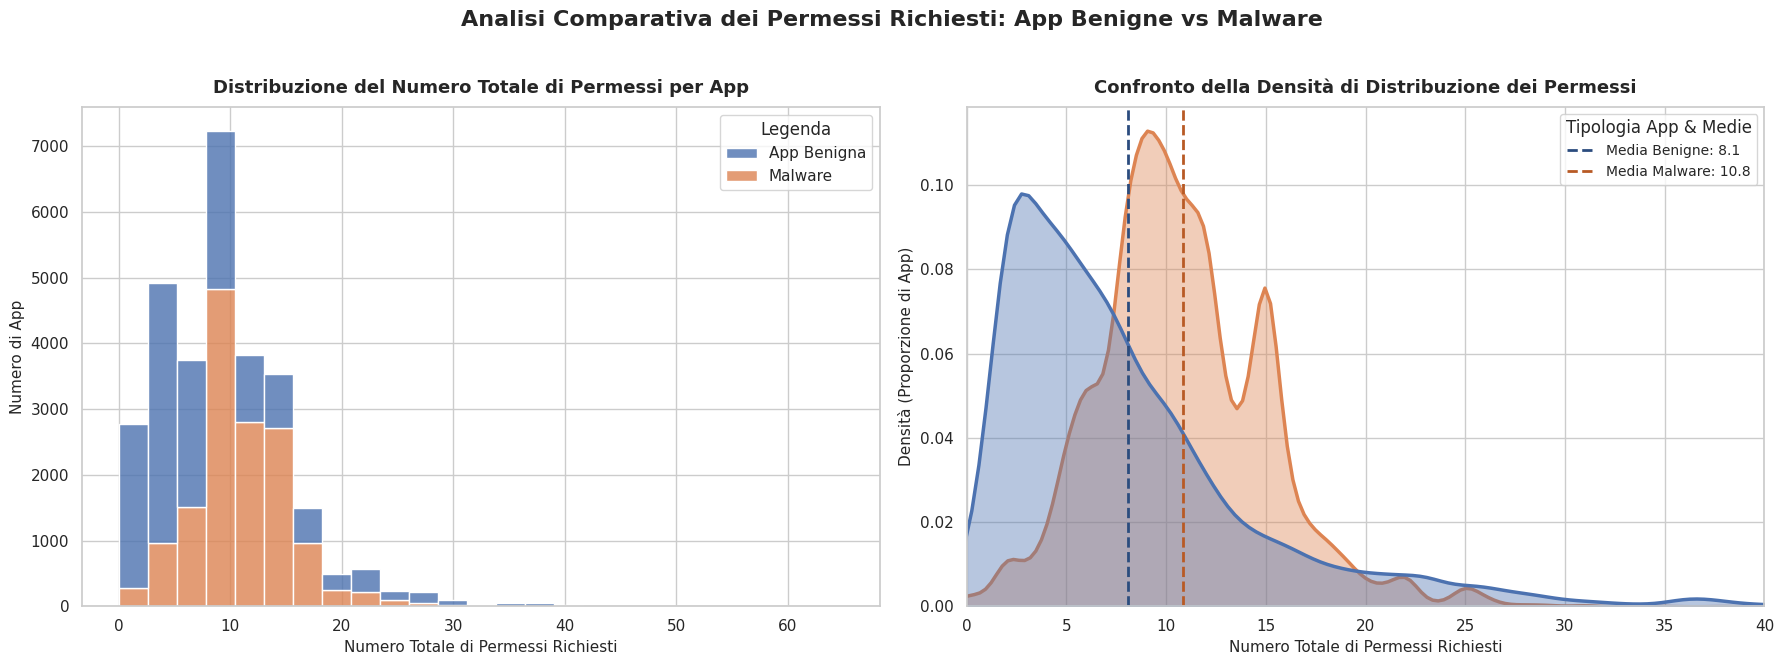

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Preparazione dati: uniamo le caratteristiche (X) e il risultato (y) in un'unica tabella (df)
df = pd.concat([X, y], axis=1)

# Mappiamo i valori della colonna Result per avere etichette chiare nella legenda
# 0 = App Benigna (blu), 1 = Malware (arancione/rosso)
df['Legenda'] = df['Result'].map({0: 'App Benigna', 1: 'Malware'})

# Calcoliamo una nuova colonna: quanti permessi richiede in totale ciascuna app
# Sommiamo i valori (1) di tutte le colonne dei permessi per ogni riga
df['total_permissions'] = X.sum(axis=1)

# Calcolo delle medie
media_benigne = df[df['Result'] == 0]['total_permissions'].mean()
media_malware = df[df['Result'] == 1]['total_permissions'].mean()

# Impostiamo lo stile generale
sns.set_theme(style="whitegrid")

# Creazione della figura con due subplots affiancati
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# --- GRAFICO 1 (Sinistra): Istogramma Stacked Originale ---
# Creiamo l'istogramma suddividendo i colori in base al target ('Result': malware vs benigno)
# 'multiple="stack"' impila le barre per vedere il totale complessivo e la proporzione
sns.histplot(
    data=df,
    x='total_permissions',
    hue='Legenda',
    bins=25,
    multiple="stack",
    palette=['#4C72B0', '#DD8452'],
    alpha=0.8,
    ax=axes[0]
)

# Aggiungiamo titolo ed etichette
axes[0].set_title('Distribuzione del Numero Totale di Permessi per App', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Numero Totale di Permessi Richiesti', fontsize=11)
axes[0].set_ylabel('Numero di App', fontsize=11)

# --- GRAFICO 2 (Destra): KDE Plot con Medie ---
sns.kdeplot(
    data=df,
    x='total_permissions',
    hue='Legenda',
    fill=True,
    common_norm=False,
    palette=['#4C72B0', '#DD8452'],
    alpha=0.4,
    linewidth=2.5,
    ax=axes[1]
)
axes[1].axvline(x=media_benigne, color='#2B4C7E', linestyle='--', linewidth=2,
                label=f'Media Benigne: {media_benigne:.1f}')
axes[1].axvline(x=media_malware, color='#B85A25', linestyle='--', linewidth=2,
                label=f'Media Malware: {media_malware:.1f}')

axes[1].set_title('Confronto della Densità di Distribuzione dei Permessi', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Numero Totale di Permessi Richiesti', fontsize=11)
axes[1].set_ylabel('Densità (Proporzione di App)', fontsize=11)
axes[1].set_xlim(0, 40)
axes[1].legend(title='Tipologia App & Medie', fontsize=10, loc='upper right')

# Titolo principale globale
plt.suptitle('Analisi Comparativa dei Permessi Richiesti: App Benigne vs Malware', fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()

# Mostriamo i grafici
plt.show()

L'istogramma mostra che le applicazioni benigne (in blu) tendono a richiedere pochissimi permessi (la maggior parte si concentra tra 0 e 5 permessi).
Al contrario, i malware (in arancione) mostrano una distribuzione spostata verso destra, richiedendo spesso tra gli 8 e i 15 permessi totali. Questo suggerisce che un numero elevato di permessi richiesti è un forte indizio di potenziale pericolosità.

Ora, per verificare che il grafico precedente sia attendibile, dobbiamo capire se il dataset che stiamo analizzando sia bilanciato. Ovvero dobbiamo capire se il numero di malware e di app benigne, all'interno del dataset, è simile.
Se il numero è simile, allora il dataset è bilanciato e il grafico soprariportato è attendibile, altrimenti dovremo calibrare in modo differente la nostra analisi

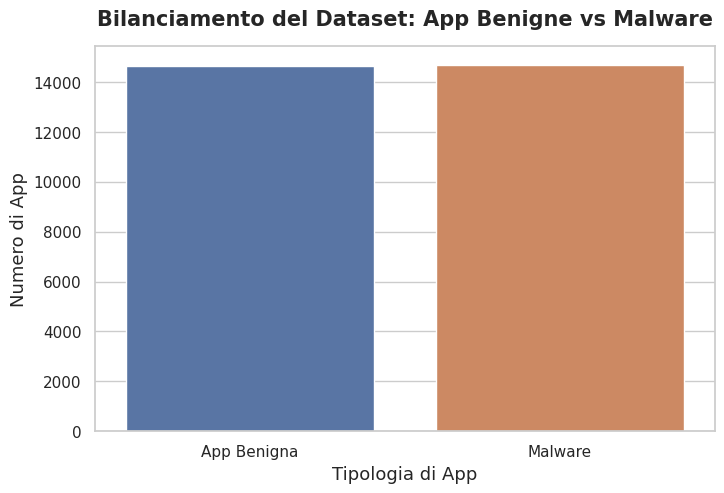

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Legenda',
    hue= 'Legenda',
    palette=['#4C72B0', '#DD8452'],
    legend = False
)
plt.title('Bilanciamento del Dataset: App Benigne vs Malware', fontsize=15, pad=15, fontweight='bold')
plt.xlabel('Tipologia di App', fontsize=13)
plt.ylabel('Numero di App', fontsize=13)
plt.show()

Il countplot mostra che il dataset è perfettamente bilanciato: circa 14.600 app benigne e 14.600 malware.
Ciò conferma che il confronto visivo fatto nell'istogramma precedente è statisticamente corretto e altamente attendibile.

Un altro aspetto da analizzare è capire quali permessi sono più richiesti dai malware rispetto alle app benigne

<Figure size 1200x600 with 0 Axes>

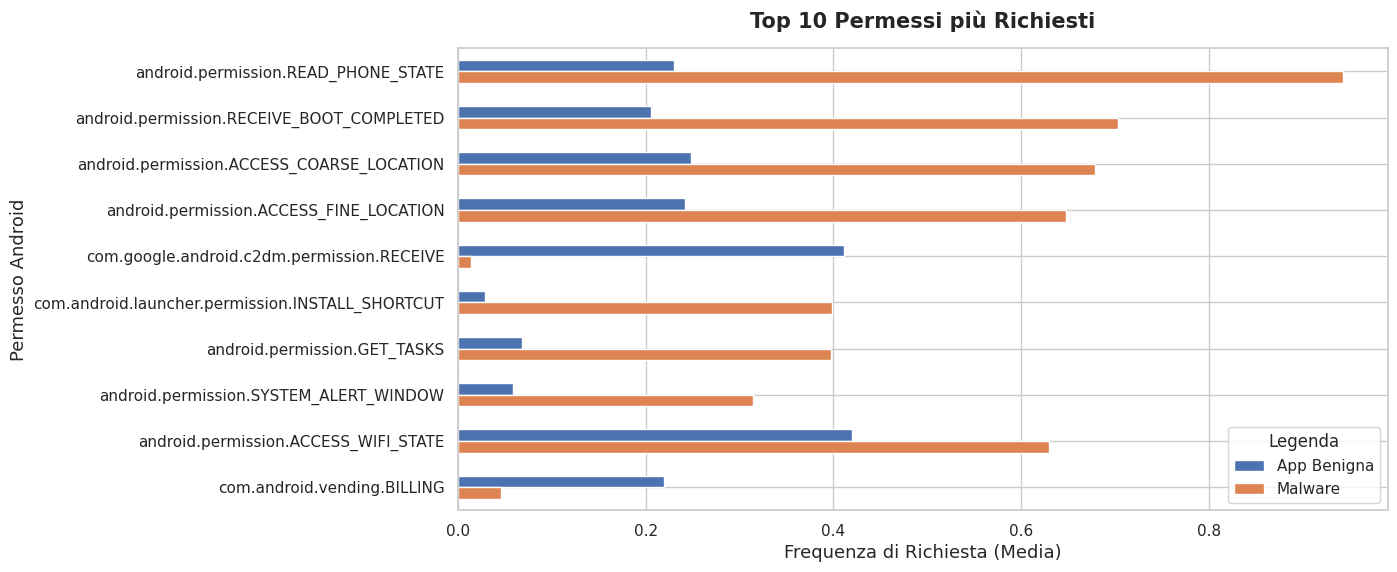

In [13]:
# Calcoliamo la percentuale di richiesta di ciascun permesso per malware e app benigne
perm_columns = X.columns
comparison = df.groupby('Legenda')[perm_columns].mean().T
comparison['Difference'] = abs(comparison['Malware'] - comparison['App Benigna'])

# Prendiamo i 10 permessi con la differenza maggiore (quelli più caratteristici)
top_permissions = comparison.sort_values(by='Difference', ascending=False).head(10)

# Creiamo il grafico a barre orizzontale
plt.figure(figsize=(12, 6))
top_permissions[['App Benigna', 'Malware']].plot(kind='barh', figsize=(12, 6), color=['#4C72B0', '#DD8452'])
plt.title('Top 10 Permessi più Richiesti', fontsize=15, pad=15, fontweight='bold')
plt.xlabel('Frequenza di Richiesta (Media)', fontsize=13)
plt.ylabel('Permesso Android', fontsize=13)
plt.gca().invert_yaxis() # Inverte l'asse per mettere il più importante in cima
plt.legend(title='Legenda')
plt.show()


Quindi, da questa analisi si vede la differenza di frequenza d'uso dei permessi tra malware e app sicure, prendendo i 10 permessi con maggiore richiesta app benigne o malevole. Si evidenzia, per esempio, che il permesso READ_PHONE_STATE (lettura dello stato del telefono) è richiesto da quasi il 94% dei malware, ma solo da circa il 23% delle app benigne.
Altri permessi fortemente associati ai malware sono RECEIVE_BOOT_COMPLETED (avvio automatico all'accensione del dispositivo) e i permessi di localizzazione geografica (ACCESS_COARSE_LOCATION, ACCESS_FINE_LOCATION).

**ANALISI ESPLORATIVA**: QUALITÀ E STRUTTURA DEI DATI

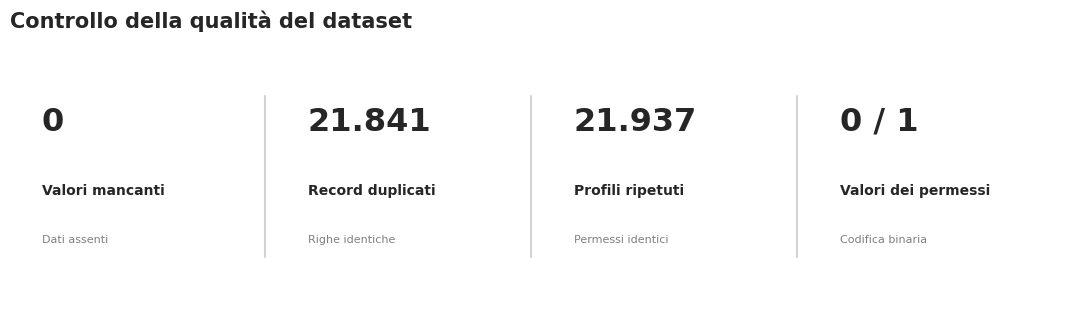

In [14]:

# ANALISI DELLA QUALITÀ DEI DATI

# Calcoliamo gli indicatori
valori_mancanti = df.isnull().sum().sum()
record_duplicati = df.duplicated().sum()
profili_ripetuti = X.duplicated().sum()

# Verifichiamo i valori presenti nelle caratteristiche
valori_permessi = sorted(X.stack().unique())

# Creiamo una visualizzazione sintetica
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.axis("off")

indicatori = [
    ("Valori mancanti", valori_mancanti, "Dati assenti"),
    ("Record duplicati", f"{record_duplicati:,}".replace(",", "."), "Righe identiche"),
    ("Profili ripetuti", f"{profili_ripetuti:,}".replace(",", "."), "Permessi identici"),
    ("Valori dei permessi", " / ".join(map(str, valori_permessi)), "Codifica binaria")
]

for i, (titolo, valore, descrizione) in enumerate(indicatori):
    x_pos = 0.03 + i * 0.25

    ax.text(x_pos, 0.72, str(valore),
            transform=ax.transAxes,
            fontsize=23, fontweight="bold")

    ax.text(x_pos, 0.48, titolo,
            transform=ax.transAxes,
            fontsize=10, fontweight="bold")

    ax.text(x_pos, 0.30, descrizione,
            transform=ax.transAxes,
            fontsize=8, color="gray")

    if i < 3:
        ax.plot([x_pos + 0.21, x_pos + 0.21],
                [0.25, 0.85],
                transform=ax.transAxes,
                color="lightgray")

ax.set_title("Controllo della qualità del dataset",
             fontsize=15, fontweight="bold",
             loc="left", pad=20)

plt.tight_layout()
plt.show()


* Valori mancanti (0): conferma che il dataset è completo e non ci sono dati assenti (nulli).
* Record duplicati (21.841): indica che ci sono moltissime applicazioni che condividono esattamente la stessa riga nel dataset (stessi permessi richiesti e stessa classificazione Benigna/Malware).
* Profili ripetuti (21.937): rappresenta il numero di righe che hanno la stessa identica combinazione di permessi (feature), a prescindere dal fatto che siano malware o benigne.
* Valori dei permessi (0 / 1): conferma che le feature sono codificate correttamente in modo binario (0 se il permesso non è richiesto, 1 se è richiesto).

Passo successivo: capire se esistono applicazioni che richiedono gli stessi identici permessi (profili identici), ma appartengono a classi diverse (una è considerata sicura/benigna e l'altra è un malware).

In [15]:

# VERIFICA DEI PROFILI DI PERMESSI CON ETICHETTE DIVERSE

gruppi = df.groupby(list(X.columns))["Result"].agg(
    numero_app="size",
    numero_classi="nunique"
)

# Individuiamo i profili associati a più di una classe
profili_conflitto = gruppi[gruppi["numero_classi"] > 1]

print("Profili di permessi associati a entrambe le classi:",
      len(profili_conflitto))

print("Applicazioni coinvolte:",
      int(profili_conflitto["numero_app"].sum()))


Profili di permessi associati a entrambe le classi: 96
Applicazioni coinvolte: 5624


In [16]:
# RIEPILOGO DEI PROFILI DI PERMESSI DISCORDANTI

distribuzione_profili = df.groupby(
    list(X.columns)
)["Result"].value_counts().unstack(fill_value=0)

discordanti = distribuzione_profili[
    (distribuzione_profili[0] > 0) &
    (distribuzione_profili[1] > 0)
]

app_benigne = int(discordanti[0].sum())
malware = int(discordanti[1].sum())
totale = app_benigne + malware

print(f"Profili discordanti (profili identici, ma classi differenti): {len(discordanti)}")
print(f"App benigne coinvolte: {app_benigne} ({app_benigne/totale:.1%})")
print(f"Malware coinvolti: {malware} ({malware/totale:.1%})")
print(f"Totale applicazioni coinvolte: {totale}")

Profili discordanti (profili identici, ma classi differenti): 96
App benigne coinvolte: 4387 (78.0%)
Malware coinvolti: 1237 (22.0%)
Totale applicazioni coinvolte: 5624


L'analisi ha individuato **96 profili identici associati a classi differenti (discordanti)**, per un totale di 5.624 applicazioni coinvolte. Di queste, 4.387 sono classificate come benigne e 1.237 come malware.

Questo risultato evidenzia un limite importante delle informazioni disponibili: **applicazioni appartenenti a classi differenti presentano una configurazione di permessi identica**. Di conseguenza, il solo insieme dei permessi richiesti non permette sempre di distinguere con certezza un'applicazione malevole da una legittima.

Questa osservazione sarà fondamentale nelle successive analisi di clustering, poiché applicazioni con lo stesso identico profilo si troveranno nello stesso identico punto dello spazio geometrico dei dati, nonostante appartengano a classi opposte.

Adesso si calcola quanti "modelli" (profili) unici di permessi esistono nel dataset.

In [17]:
# ANALISI DEI PROFILI DI PERMESSI DISTINTI

profili_unici = X.drop_duplicates()

print("Numero totale di applicazioni:", len(X))
print("Numero di profili di permessi distinti:", len(profili_unici))
print("Profili ripetuti:", len(X) - len(profili_unici))

Numero totale di applicazioni: 29332
Numero di profili di permessi distinti: 7395
Profili ripetuti: 21937


Quindi su 29.332 applicazioni totali, esistono solo 7.395 profili di permessi distinti.
Questo significa che la stragrande maggioranza delle applicazioni (21.937) non fa altro che replicare combinazioni di permessi già viste in altre app.

Analisi di quanto sono comuni i vari profili di permessi

Numero di profili distinti: 7395
Profilo più frequente: 2009 applicazioni
Profili presenti una sola volta: 5347


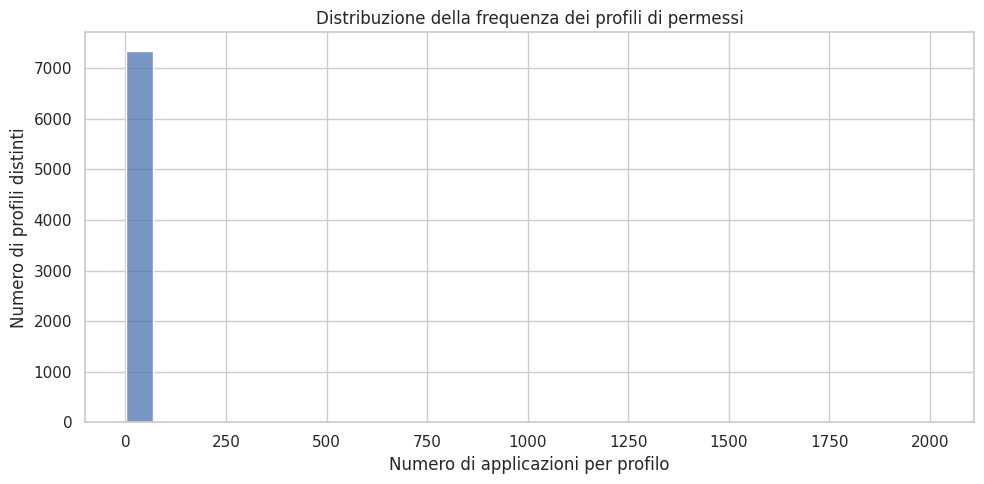

In [18]:
# FREQUENZA DEI PROFILI DI PERMESSI

frequenze_profili = X.value_counts()

print("Numero di profili distinti:", len(frequenze_profili))
print("Profilo più frequente:", frequenze_profili.max(), "applicazioni")
print("Profili presenti una sola volta:", (frequenze_profili == 1).sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    frequenze_profili,
    bins=30,
    color="#4C72B0"
)

plt.title("Distribuzione della frequenza dei profili di permessi")
plt.xlabel("Numero di applicazioni per profilo")
plt.ylabel("Numero di profili distinti")
plt.tight_layout()
plt.show()

* Profilo più frequente: esiste una specifica combinazione di permessi che viene utilizzata da ben 2.009 applicazioni.
* Profili unici: Ci sono 5.347 profili che compaiono una sola volta nel dataset (ossia appartengono a una sola specifica app).
* Istogramma: mostra una distribuzione fortemente sbilanciata verso sinistra. La quasi totalità dei profili di permessi è usata pochissime volte (spesso una sola volta, barra alta vicino allo 0), mentre pochissimi profili standard (come quello da 2.009 app) coprono la stragrande maggioranza del dataset.